# Priyanshu Kumar Singh [CSE(AI & ML) 3rd year]

# Topic :- Student Academic Performance Prediction Using Machine Learning

## Introduction:
This project aims to predict students' academic performance using machine learning techniques. By analysing factors such as study time, attendance, previous grades, and other academic attributes, the system identifies students who may be at risk of poor performance. It uses classification algorithms to categorise students into different performance levels, helping educators identify those who may need additional academic support.

# Importing Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


# Loading the dataset

In [4]:
df = pd.read_csv("student-por.csv")

print("Dataset loaded successfully!")

df

Dataset loaded successfully!


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10


In [5]:
# here, the dataset, in the form of csv file, which we downloaded and saved locally, has been loaded successfully

# Displaying the data

In [6]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [7]:
# Using the pandas, we are successful in viewing the first 5 students' records

# Check Data dimensions

In [8]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (649, 33)


In [9]:
# the Number of rows and columns came out to be (649, 33) respectively.

# Display column names

In [10]:
print("Dataset Columns:\n")

for column in df.columns:
    print(column)

Dataset Columns:

school
sex
age
address
famsize
Pstatus
Medu
Fedu
Mjob
Fjob
reason
guardian
traveltime
studytime
failures
schoolsup
famsup
paid
activities
nursery
higher
internet
romantic
famrel
freetime
goout
Dalc
Walc
health
absences
G1
G2
G3


In [11]:
# The column names has successfully been displayed, as present in the dataset.

# Checking the dataset information

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [13]:
# Using the pandas' tool of info, the information of the dataset has successfully been displayed, as present in the dataset.

# The Statistical summary of the dataset is as follows:

In [14]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [15]:
#This gives statistical information such as mean, standard deviation, minimum, maximum and quartiles for numerical columns.

# Data preprocessing and exploratory data analysis (EDA)

In [16]:
#Check for missing values

In [17]:
# Check missing values in each column

print("Missing values in dataset:\n")

print(df.isnull().sum())

Missing values in dataset:

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [18]:
# Using isnull feature of pandas, we've removed the null valued entries from the dataset.

# Checking for total missing values

In [19]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [20]:
# here, the dataset has successfully been cleared out of any missing values.

# Checking duplicate records:

In [21]:
print("Total duplicate records:", df.duplicated().sum())

Total duplicate records: 0


In [22]:
# the dataset has successfully been cleared out of any duplicate values

Now that the basic cleaning and checks for any faulty entries in the dataset has been cleaned and sorted out, lets Create performance categories:

# Creating performance categories

In [23]:
def categorize_performance(grade):

    if grade <= 9:
        return "At Risk"

    elif grade <= 13:
        return "Average"

    else:
        return "Good"


df["Performance"] = df["G3"].apply(categorize_performance)

print("Performance categories created successfully!")

df[["G3", "Performance"]].head(10)

Performance categories created successfully!


,G3,Performance
0,11,Average
1,11,Average
2,12,Average
3,14,Good
4,13,Average
5,13,Average
6,13,Average
7,13,Average
8,17,Good
9,13,Average


#The following output shows the performance measure of the first 10 students of G3,for an example, based on the performance categories we've just created.

# Category distribution

In [25]:
print("Student Performance Distribution:\n")

print(df["Performance"].value_counts())

Student Performance Distribution:

Performance
Average    355
Good       194
At Risk    100
Name: count, dtype: int64


In [26]:
# Here, using pandas' value_counts() tool, we found out how many students belong to each performance category.

Let's visualise the distribution

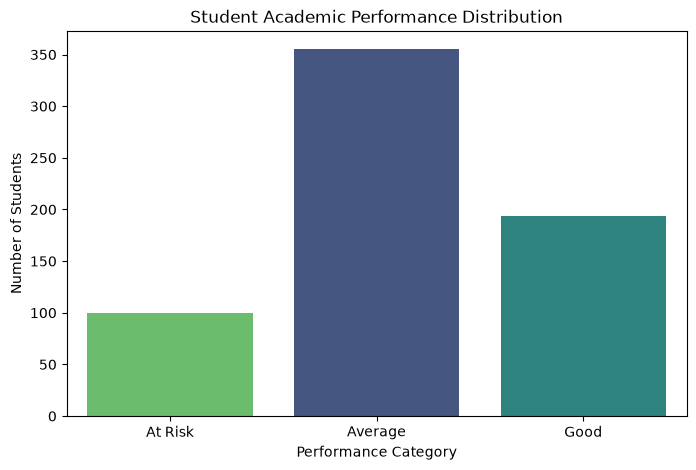

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Performance",
    hue="Performance",
    order=["At Risk", "Average", "Good"],
    palette="viridis",
    legend=False
)

plt.title("Student Academic Performance Distribution")

plt.xlabel("Performance Category")

plt.ylabel("Number of Students")

plt.show()

In [28]:
#This graph shows how many students are performing well, moderately, or are at risk.

#Let's do an Analysis of study time and academic performance.

# Study time analysis

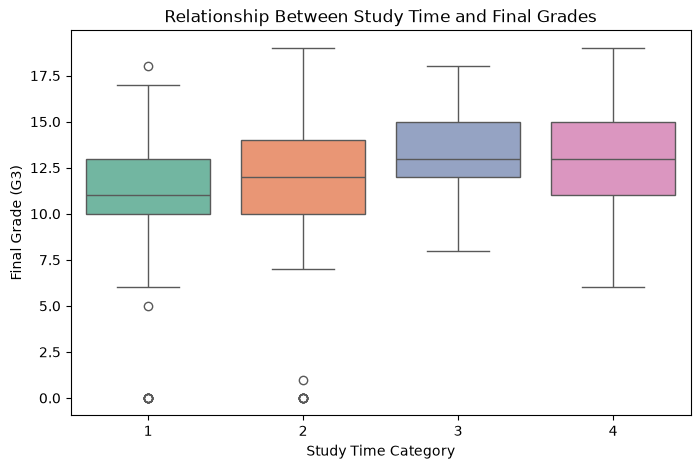

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="studytime",
    y="G3",
    hue="studytime",
    palette="Set2",
    legend=False
)

plt.title("Relationship Between Study Time and Final Grades")

plt.xlabel("Study Time Category")

plt.ylabel("Final Grade (G3)")

plt.show()

In [30]:
#This graph helps us examine how final grades vary across study-time groups.

# Analysing the impact of absences

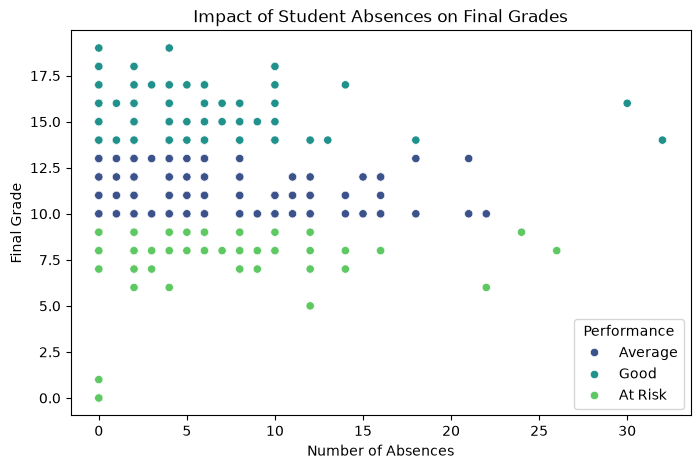

In [31]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3",
    hue="Performance",
    palette="viridis"
)

plt.title("Impact of Student Absences on Final Grades")

plt.xlabel("Number of Absences")

plt.ylabel("Final Grade")

plt.show()

# Analysing previous academic failures

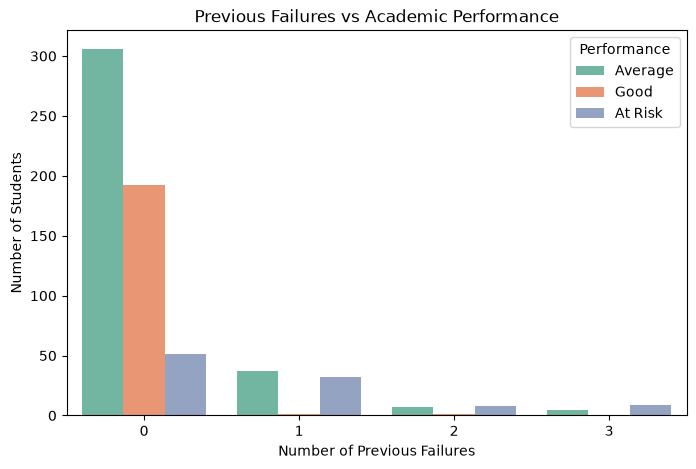

In [33]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="failures",
    hue="Performance",
    palette="Set2"
)

plt.title("Previous Failures vs Academic Performance")

plt.xlabel("Number of Previous Failures")

plt.ylabel("Number of Students")

plt.show()

# Plotting Correlation analysis using Heatmap:

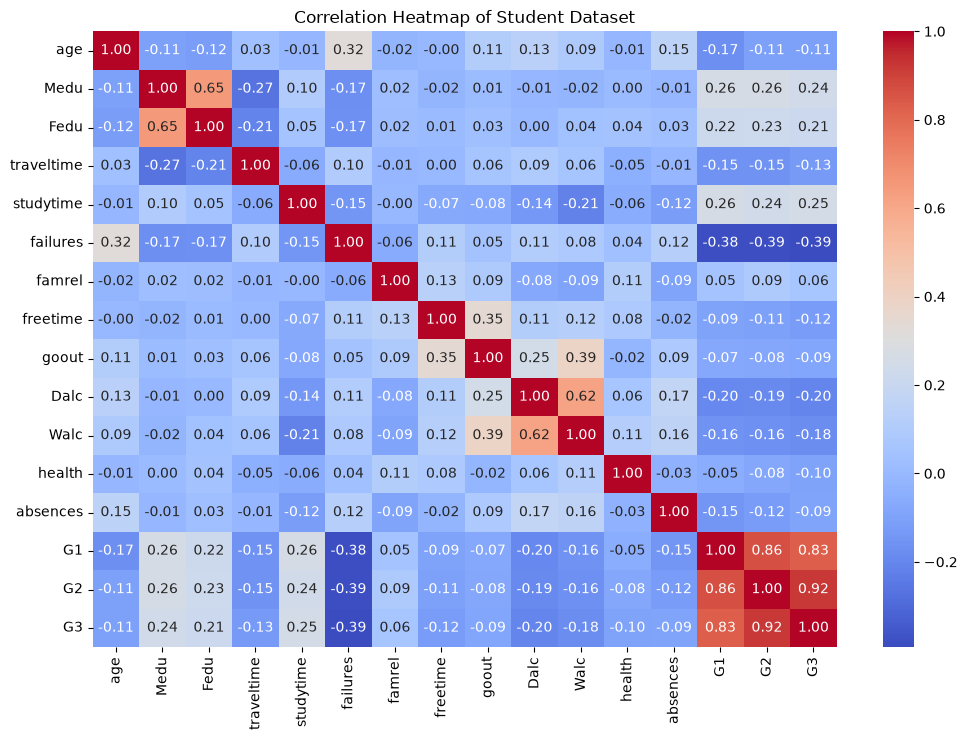

In [34]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Student Dataset")

plt.show()

In [35]:
#Let's now proceed to select the features and data preprocession.

# Feature selection and data preprocessing

In [36]:
# Remove grade columns and target column

X = df.drop(
    columns=["G1", "G2", "G3", "Performance"]
)

# Store target variable separately

y = df["Performance"]

print("Feature selection completed!")

print("Input features:", X.shape)

print("Target variable:", y.shape)

Feature selection completed!
Input features: (649, 30)
Target variable: (649,)


In [37]:
# We now have 30 input features and one target variable.

Identification of categorical and numerical columns

In [38]:
# Identify numerical columns

numerical_columns = X.select_dtypes(
    include=["number"]
).columns

# Identify categorical columns

categorical_columns = X.select_dtypes(
    include=["object", "str"]
).columns

print("Numerical columns:")
print(list(numerical_columns))

print("\nCategorical columns:")
print(list(categorical_columns))

Numerical columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


Converting categorical data into numerical data, using One-Hot Encoding

In [39]:
# Convert categorical variables into numerical variables

X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

print("Categorical data converted successfully!")

print("New dataset shape:", X.shape)

X.head()

Categorical data converted successfully!
New dataset shape: (649, 39)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,0,4,3,2,2,...,1,0,1,0,0,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,0,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,0,0,1,1,0,0


# Target distribution

In [40]:
print("Target Variable Distribution:\n")

print(y.value_counts())

Target Variable Distribution:

Performance
Average    355
Good       194
At Risk    100
Name: count, dtype: int64


The target variable distribution of the students into three groups - average, good, bad has been done, accordingly to their marks.

# Train-test split

In [41]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset splitting completed!")

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)

print("Testing target:", y_test.shape)

Dataset splitting completed!
Training data: (519, 39)
Testing data: (130, 39)
Training target: (519,)
Testing target: (130,)


In [42]:
# We've successfully splitted our training and testing data

# Model Training

In [43]:
# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

# Create the model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [44]:
#Upon successfully having the model trained, lets train and predict with a decision tree classifier:

# Decision Tree Classifier

In [45]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.tree import DecisionTreeClassifier

# Initialize and train the Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Predict on the test set
y_pred_dt = dt_model.predict(X_test)

# Evaluate performance
dt_accuracy = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Accuracy: {dt_accuracy:.4f}")
print("\nConfusion Matrix (Decision Tree):")
print(confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report (Decision Tree):")
print(
    classification_report(
        y_test, y_pred_dt, target_names=["At Risk", "Average", "Good"]
    )
)

Decision Tree Accuracy: 0.4615

Confusion Matrix (Decision Tree):
[[ 3 12  5]
 [ 6 42 23]
 [ 1 23 15]]

Classification Report (Decision Tree):
              precision    recall  f1-score   support

     At Risk       0.30      0.15      0.20        20
     Average       0.55      0.59      0.57        71
        Good       0.35      0.38      0.37        39

    accuracy                           0.46       130
   macro avg       0.40      0.38      0.38       130
weighted avg       0.45      0.46      0.45       130



In [46]:
# here, we've sussessfully calculated the decision tree accuracy, i.e. 46.15%, together with the classification report and confusion matrix.

# Training and evaluating a Random Forest Classifier

In [47]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# Initialize and train the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict on the test set
y_pred_rf = rf_model.predict(X_test)

# Evaluate performance
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print("\nConfusion Matrix (Random Forest):")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report (Random Forest):")
print(
    classification_report(
        y_test, y_pred_rf, target_names=["At Risk", "Average", "Good"]
    )
)

Random Forest Accuracy: 0.6308

Confusion Matrix (Random Forest):
[[ 3 12  5]
 [ 2 64  5]
 [ 0 24 15]]

Classification Report (Random Forest):
              precision    recall  f1-score   support

     At Risk       0.60      0.15      0.24        20
     Average       0.64      0.90      0.75        71
        Good       0.60      0.38      0.47        39

    accuracy                           0.63       130
   macro avg       0.61      0.48      0.49       130
weighted avg       0.62      0.63      0.59       130



#Similar to that of the decision tree, the random forest classifier's accuracy, confusion matrix, and the classification report has successfully been displayed.

In [48]:
# Let's now compare the both models, to see which works better and much accurately

# Side-by-Side Comparison & Visual Confusion Matrices

,Metric,Decision Tree,Random Forest
0,Accuracy,0.4615,0.6308
1,Macro Precision,0.3981,0.6133
2,Macro Recall,0.3754,0.4787
3,Weighted Precision,0.4487,0.6218
4,Weighted Recall,0.4615,0.6308


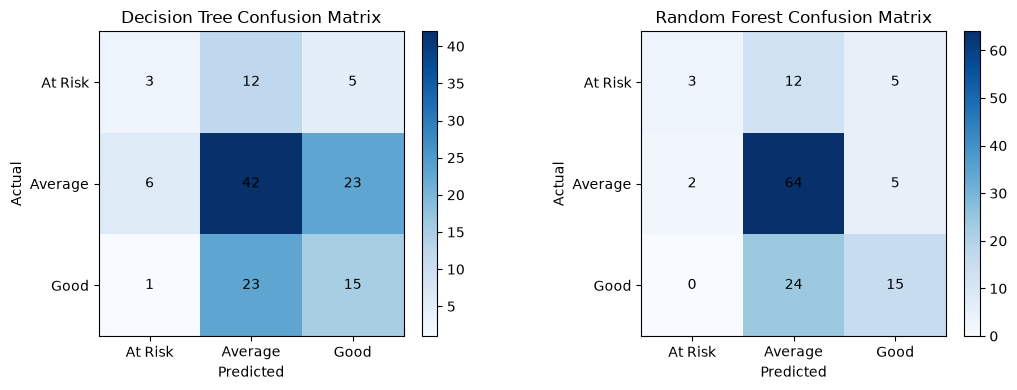

In [49]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import precision_score, recall_score

comparison_df = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Macro Precision",
            "Macro Recall",
            "Weighted Precision",
            "Weighted Recall",
        ],
        "Decision Tree": [
            accuracy_score(y_test, y_pred_dt),
            precision_score(
                y_test, y_pred_dt, average="macro", zero_division=0
            ),
            recall_score(y_test, y_pred_dt, average="macro", zero_division=0),
            precision_score(
                y_test, y_pred_dt, average="weighted", zero_division=0
            ),
            recall_score(
                y_test, y_pred_dt, average="weighted", zero_division=0
            ),
        ],
        "Random Forest": [
            accuracy_score(y_test, y_pred_rf),
            precision_score(
                y_test, y_pred_rf, average="macro", zero_division=0
            ),
            recall_score(y_test, y_pred_rf, average="macro", zero_division=0),
            precision_score(
                y_test, y_pred_rf, average="weighted", zero_division=0
            ),
            recall_score(
                y_test, y_pred_rf, average="weighted", zero_division=0
            ),
        ],
    }
).round(4)

display(comparison_df)

# Side-by-side Confusion Matrices
labels = ["At Risk", "Average", "Good"]
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, cm, title in zip(
    axes,
    [cm_dt, cm_rf],
    ["Decision Tree Confusion Matrix", "Random Forest Confusion Matrix"],
):
  im = ax.imshow(cm, cmap="Blues")
  ax.set_title(title)
  ax.set_xticks(range(len(labels)))
  ax.set_yticks(range(len(labels)))
  ax.set_xticklabels(labels)
  ax.set_yticklabels(labels)
  ax.set_xlabel("Predicted")
  ax.set_ylabel("Actual")
  for i in range(len(labels)):
    for j in range(len(labels)):
      ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
  fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [50]:
# the comparative plotting of the decision tree and random forest classifiers has been plotted using matplotlibb.

# Inspect Top Feature Importances (Random Forest)

absences    0.0567
age         0.0533
Medu        0.0515
health      0.0480
goout       0.0475
failures    0.0474
Walc        0.0465
freetime    0.0461
Fedu        0.0440
famrel      0.0428
dtype: float64

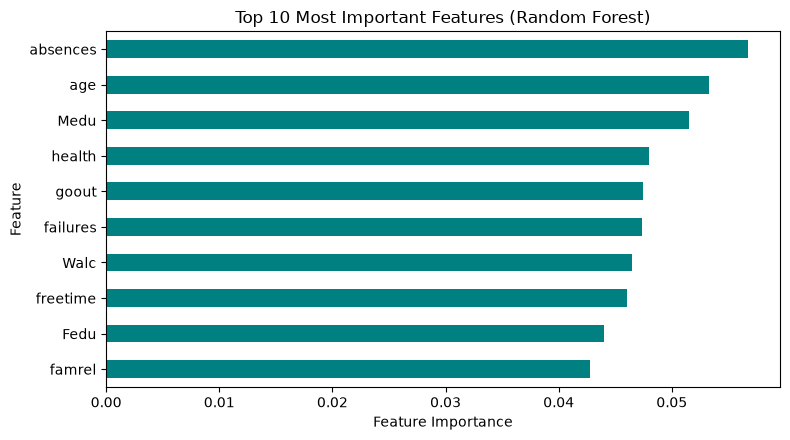

In [51]:
import numpy as np

importances = pd.Series(
    rf_model.feature_importances_, index=X_train.columns
).sort_values(ascending=False)

top_n = 10
display(importances.head(top_n).round(4))

plt.figure(figsize=(8, 4.5))
importances.head(top_n).iloc[::-1].plot(kind="barh", color="teal")
plt.title(f"Top {top_n} Most Important Features (Random Forest)")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [52]:
# the display of top 10 most important features, using the random forest has been portrayed.

### Conclusion & Key Takeaways

Best Model: Random Forest performed significantly better (63.08% accuracy) than a single Decision Tree (46.15% accuracy) because combining multiple trees reduces overfitting.
Key Predictors: Student absences, age, and parental education (Medu) were the strongest indicators of academic performance, allowing the model to flag risk factors early without relying on mid-term grades.
Limitation & Future Scope: While overall accuracy is solid, recall for the At Risk class was low (15%) due to class imbalance. Collecting more balanced data or tuning class weights could help catch more struggling students in future versions.
